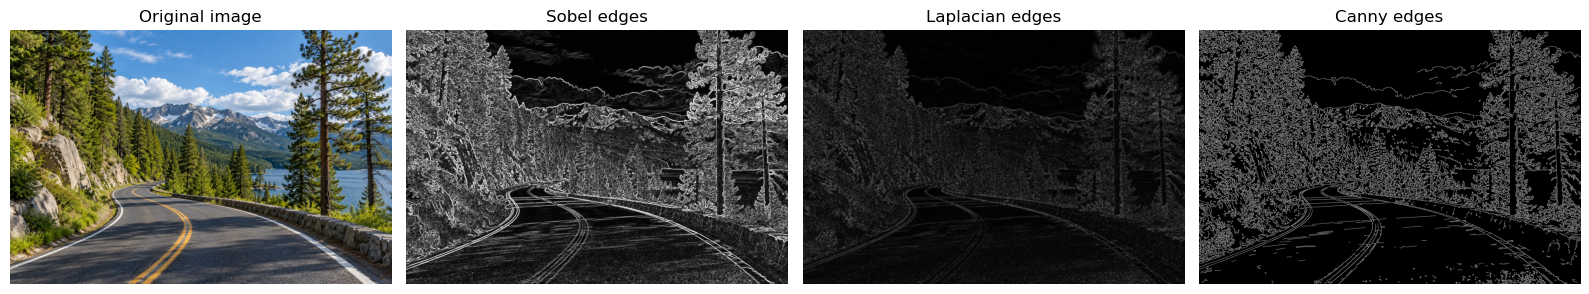

Analysis:
- Sobel detects horizontal and vertical intensity changes and shows edge strength.
- Laplacian detects rapid intensity changes in all directions, but is sensitive to noise.
- Canny uses smoothing, gradient calculation, non-maximum suppression and hysteresis thresholds.
- Canny generally gives thin, connected and meaningful boundaries. Sobel is useful when edge strength is important.


In [3]:
#Problem 1 – Comparative Edge Detection on Natural Images

import cv2
import matplotlib.pyplot as plt

image = cv2.imread("outdoor_natural.jpg")
if image is None:
    raise FileNotFoundError("outdoor_natural.jpg not found. Extract the sample ZIP beside this notebook.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 1.0)

sx = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
sy = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sx, sy))
laplacian = cv2.convertScaleAbs(cv2.Laplacian(blur, cv2.CV_64F))
canny = cv2.Canny(blur, 80, 160)

fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for a, im, title, cmap in zip(
    ax,
    [cv2.cvtColor(image, cv2.COLOR_BGR2RGB), sobel, laplacian, canny],
    ["Original image", "Sobel edges", "Laplacian edges", "Canny edges"],
    [None, "gray", "gray", "gray"]
):
    a.imshow(im, cmap=cmap); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

print("Analysis:")
print("- Sobel detects horizontal and vertical intensity changes and shows edge strength.")
print("- Laplacian detects rapid intensity changes in all directions, but is sensitive to noise.")
print("- Canny uses smoothing, gradient calculation, non-maximum suppression and hysteresis thresholds.")
print("- Canny generally gives thin, connected and meaningful boundaries. Sobel is useful when edge strength is important.")

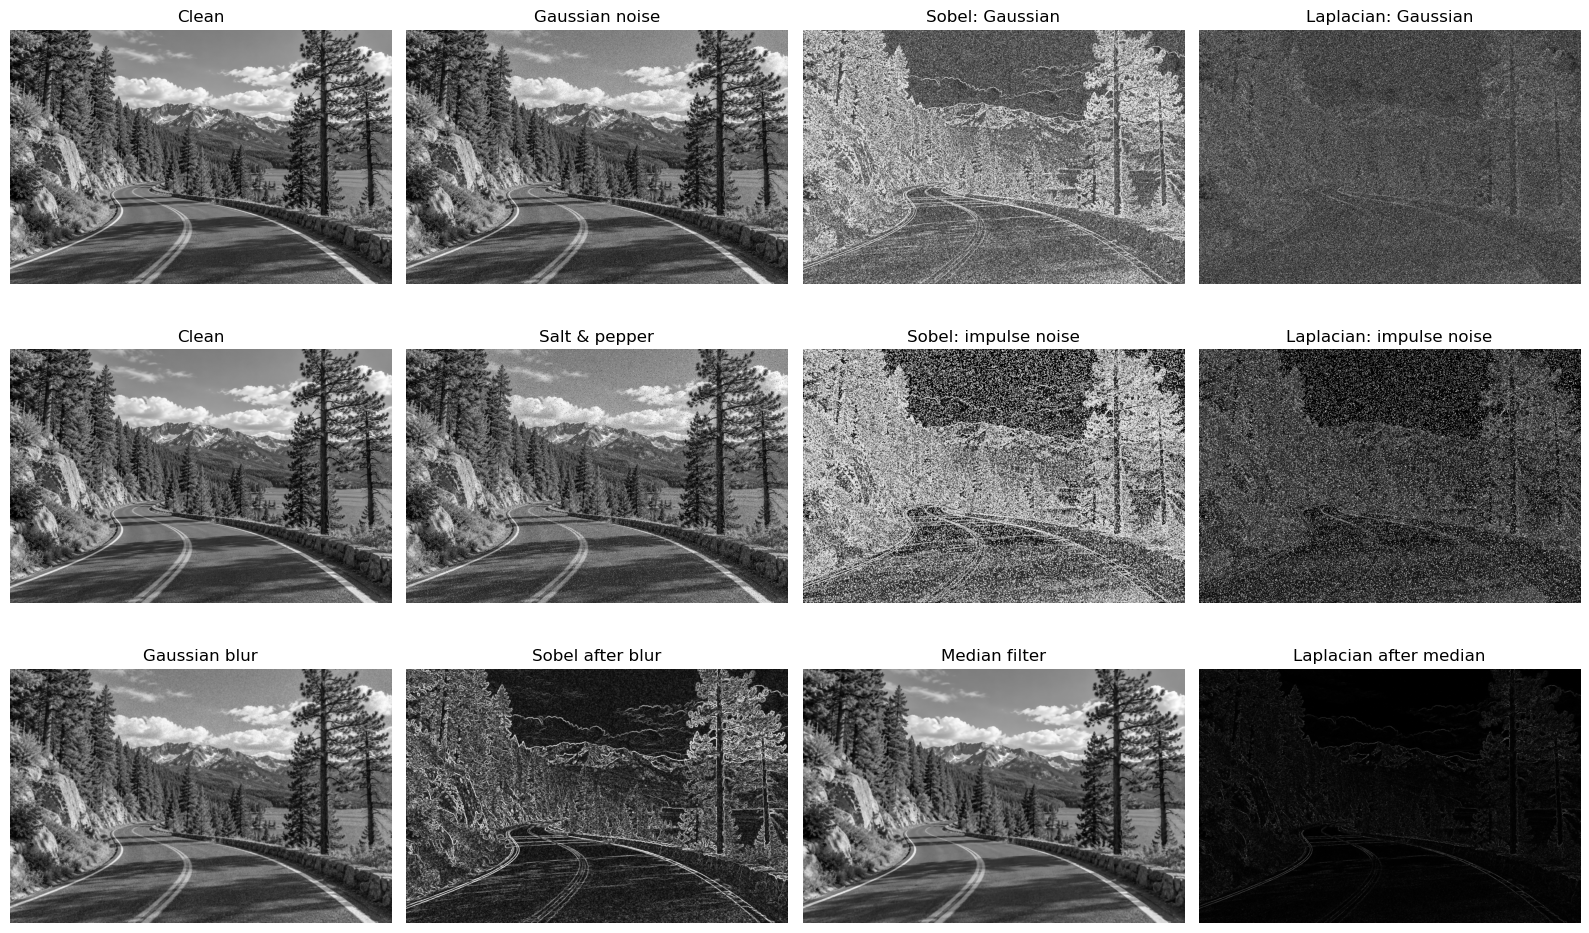

Mean edge response (may include both real edges and noise):
Sobel on Gaussian noise: 128.45
Laplacian on Gaussian noise: 78.26
Sobel after Gaussian blur: 63.07
Laplacian after Gaussian blur: 6.96
Sobel on salt-and-pepper noise: 127.93
Laplacian on salt-and-pepper noise: 58.91
Sobel after median filter: 49.30
Laplacian after median filter: 8.50

Observations:
- Laplacian is generally more affected by noise because it responds strongly to rapid intensity changes.
- Noise creates false edges and reduces the clarity of actual boundaries.
- Gaussian blur helps reduce Gaussian noise; median filtering is effective for salt-and-pepper noise.
- Excessive smoothing can also remove small genuine edges.


In [5]:
#Problem 2 – Noise Sensitivity Experiment

import cv2
import numpy as np
import matplotlib.pyplot as plt

clean = cv2.imread("outdoor_natural.jpg", cv2.IMREAD_GRAYSCALE)
if clean is None:
    raise FileNotFoundError("outdoor_natural.jpg not found. Extract the sample ZIP beside this notebook.")

rng = np.random.default_rng(42)
gaussian_noisy = np.clip(clean.astype(float) + rng.normal(0, 20, clean.shape), 0, 255).astype(np.uint8)

sp_noisy = clean.copy()
mask = rng.random(clean.shape)
sp_noisy[mask < 0.025] = 0
sp_noisy[mask > 0.975] = 255

def edge_pair(img):
    gx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
    sob = cv2.convertScaleAbs(cv2.magnitude(gx, gy))
    lap = cv2.convertScaleAbs(cv2.Laplacian(img, cv2.CV_64F))
    return sob, lap

gaussian_filtered = cv2.GaussianBlur(gaussian_noisy, (5, 5), 1.2)
sp_filtered = cv2.medianBlur(sp_noisy, 5)

sob_g, lap_g = edge_pair(gaussian_noisy)
sob_gf, lap_gf = edge_pair(gaussian_filtered)
sob_sp, lap_sp = edge_pair(sp_noisy)
sob_spf, lap_spf = edge_pair(sp_filtered)

fig, ax = plt.subplots(3, 4, figsize=(16, 10))
items = [
    (clean,"Clean"), (gaussian_noisy,"Gaussian noise"), (sob_g,"Sobel: Gaussian"), (lap_g,"Laplacian: Gaussian"),
    (clean,"Clean"), (sp_noisy,"Salt & pepper"), (sob_sp,"Sobel: impulse noise"), (lap_sp,"Laplacian: impulse noise"),
    (gaussian_filtered,"Gaussian blur"), (sob_gf,"Sobel after blur"), (sp_filtered,"Median filter"), (lap_spf,"Laplacian after median")
]
for a, (im, title) in zip(ax.flat, items):
    a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

print("Mean edge response (may include both real edges and noise):")
for name, result in [
    ("Sobel on Gaussian noise", sob_g), ("Laplacian on Gaussian noise", lap_g),
    ("Sobel after Gaussian blur", sob_gf), ("Laplacian after Gaussian blur", lap_gf),
    ("Sobel on salt-and-pepper noise", sob_sp), ("Laplacian on salt-and-pepper noise", lap_sp),
    ("Sobel after median filter", sob_spf), ("Laplacian after median filter", lap_spf)
]:
    print(f"{name}: {result.mean():.2f}")

print("\nObservations:")
print("- Laplacian is generally more affected by noise because it responds strongly to rapid intensity changes.")
print("- Noise creates false edges and reduces the clarity of actual boundaries.")
print("- Gaussian blur helps reduce Gaussian noise; median filtering is effective for salt-and-pepper noise.")
print("- Excessive smoothing can also remove small genuine edges.")

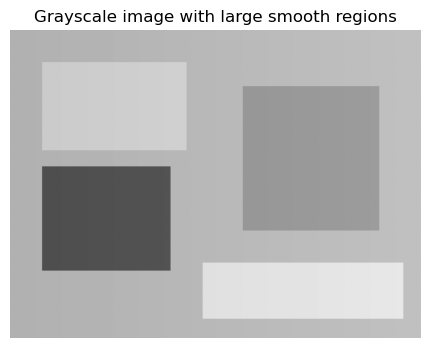

Image size: 256 x 192 pixels
Original bit length: 393,216 bits
RLE bit length: 90,096 bits
RLE percentage reduction: 77.09%
Huffman bit length: 258,258 bits
Huffman percentage reduction: 34.32%
Number of RLE runs: 3754; distinct grayscale values: 44

Explanation:
- RLE is effective when many consecutive pixels have the same value.
- Huffman coding assigns shorter codes to frequent values and longer codes to rare values.
- These are payload bit counts; actual file formats also need headers and coding information.


In [6]:
#Problem 3 – Compression Ratio Comparison (RLE vs Huffman)

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import heapq
from collections import Counter

gray = np.array(Image.open("compression_gray.png").convert("L"))
plt.figure(figsize=(7, 4))
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale image with large smooth regions")
plt.axis("off"); plt.show()

pixels = gray.ravel()
original_bits = pixels.size * 8

def calculate_rle_bits(data):
    if len(data) == 0:
        return 0, 0
    runs = 1
    previous = int(data[0])
    count = 1
    for item in data[1:]:
        item = int(item)
        if item == previous and count < 65535:
            count += 1
        else:
            runs += 1
            previous, count = item, 1
    return runs * 24, runs

def calculate_huffman_bits(data):
    freq = Counter(map(int, data))
    heap = []
    serial = 0
    for symbol, count in freq.items():
        heapq.heappush(heap, (count, serial, symbol)); serial += 1
    if len(heap) == 1:
        return len(data), 1
    while len(heap) > 1:
        f1, _, left = heapq.heappop(heap)
        f2, _, right = heapq.heappop(heap)
        heapq.heappush(heap, (f1 + f2, serial, (left, right))); serial += 1
    lengths = {}
    def visit(node, depth):
        if isinstance(node, int):
            lengths[node] = depth
        else:
            visit(node[0], depth + 1); visit(node[1], depth + 1)
    visit(heap[0][2], 0)
    bits = sum(freq[symbol] * lengths[symbol] for symbol in freq)
    return bits, len(freq)

rle_bits, run_count = calculate_rle_bits(pixels)
huffman_bits, unique_values = calculate_huffman_bits(pixels)

def reduction(before, after):
    return (before - after) / before * 100

print(f"Image size: {gray.shape[1]} x {gray.shape[0]} pixels")
print(f"Original bit length: {original_bits:,} bits")
print(f"RLE bit length: {rle_bits:,} bits")
print(f"RLE percentage reduction: {reduction(original_bits, rle_bits):.2f}%")
print(f"Huffman bit length: {huffman_bits:,} bits")
print(f"Huffman percentage reduction: {reduction(original_bits, huffman_bits):.2f}%")
print(f"Number of RLE runs: {run_count}; distinct grayscale values: {unique_values}")

print("\nExplanation:")
print("- RLE is effective when many consecutive pixels have the same value.")
print("- Huffman coding assigns shorter codes to frequent values and longer codes to rare values.")
print("- These are payload bit counts; actual file formats also need headers and coding information.")

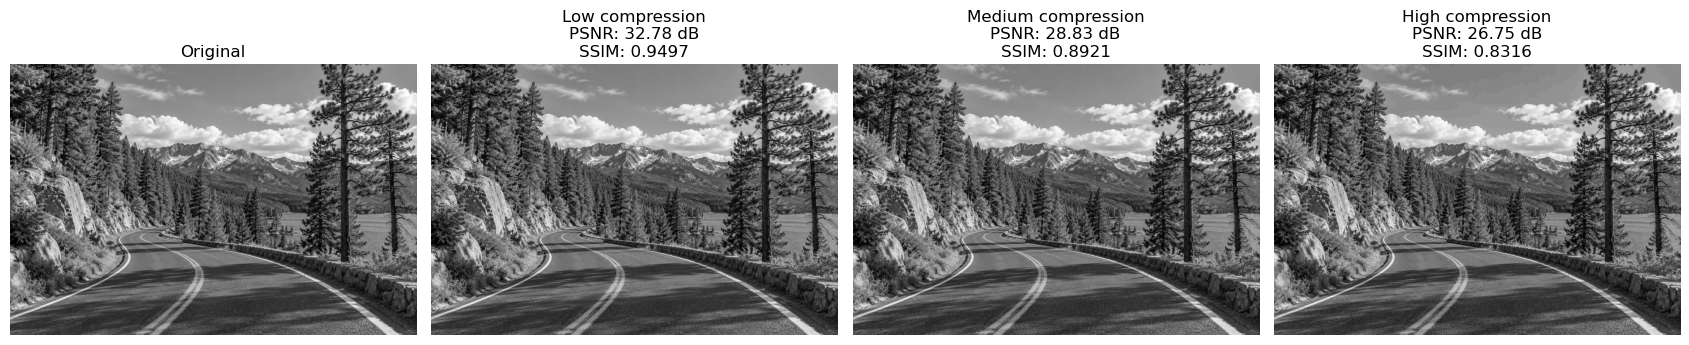

Low compression: PSNR = 32.78 dB, SSIM = 0.9497
Medium compression: PSNR = 28.83 dB, SSIM = 0.8921
High compression: PSNR = 26.75 dB, SSIM = 0.8316

Analysis:
- Block artefacts may appear near boundaries because the image is processed in separate 8x8 blocks.
- Fine textures lose detail when high-frequency DCT coefficients are quantised.
- Stronger quantisation generally lowers PSNR and SSIM, showing greater distortion.
- This is a JPEG-style demonstration; it does not implement the complete JPEG file format.


In [7]:
#Problem 4 – JPEG Block Artifact Analysis

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

bgr = cv2.imread("outdoor_natural.jpg")
if bgr is None:
    raise FileNotFoundError("outdoor_natural.jpg not found. Extract the sample ZIP beside this notebook.")
original = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

Q = np.array([
 [16,11,10,16,24,40,51,61], [12,12,14,19,26,58,60,55],
 [14,13,16,24,40,57,69,56], [14,17,22,29,51,87,80,62],
 [18,22,37,56,68,109,103,77], [24,35,55,64,81,104,113,92],
 [49,64,78,87,103,121,120,101], [72,92,95,98,112,100,103,99]
], dtype=np.float32)

def jpeg_demo(gray, scale):
    h, w = gray.shape
    ph, pw = (8-h%8)%8, (8-w%8)%8
    padded = cv2.copyMakeBorder(gray, 0, ph, 0, pw, cv2.BORDER_REFLECT)
    output = np.zeros(padded.shape, dtype=np.float32)
    qmatrix = Q * scale
    for y in range(0, padded.shape[0], 8):
        for x in range(0, padded.shape[1], 8):
            block = padded[y:y+8, x:x+8].astype(np.float32) - 128
            coeff = cv2.dct(block)
            quantised = np.round(coeff / qmatrix)
            restored = cv2.idct(quantised * qmatrix) + 128
            output[y:y+8, x:x+8] = restored
    return np.clip(np.round(output[:h, :w]), 0, 255).astype(np.uint8)

levels = [("Low compression", 0.5), ("Medium compression", 1.5), ("High compression", 3.0)]
results = []
for label, scale in levels:
    reconstructed = jpeg_demo(original, scale)
    psnr = peak_signal_noise_ratio(original, reconstructed, data_range=255)
    ssim = structural_similarity(original, reconstructed, data_range=255)
    results.append((label, reconstructed, psnr, ssim))

fig, ax = plt.subplots(1, 4, figsize=(17, 5))
ax[0].imshow(original, cmap="gray"); ax[0].set_title("Original")
for a, (label, im, psnr, ssim) in zip(ax[1:], results):
    a.imshow(im, cmap="gray")
    a.set_title(f"{label}\nPSNR: {psnr:.2f} dB\nSSIM: {ssim:.4f}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

for label, im, psnr, ssim in results:
    print(f"{label}: PSNR = {psnr:.2f} dB, SSIM = {ssim:.4f}")

print("\nAnalysis:")
print("- Block artefacts may appear near boundaries because the image is processed in separate 8x8 blocks.")
print("- Fine textures lose detail when high-frequency DCT coefficients are quantised.")
print("- Stronger quantisation generally lowers PSNR and SSIM, showing greater distortion.")
print("- This is a JPEG-style demonstration; it does not implement the complete JPEG file format.")

C:\Users\harsh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\harsh\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\harsh\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\harsh\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

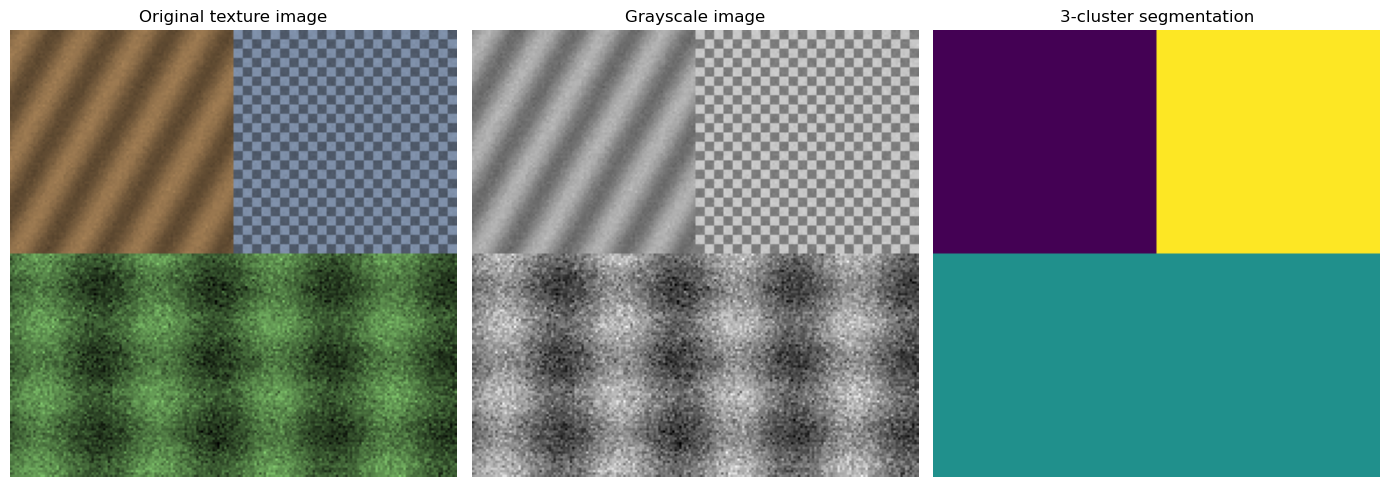

GLCM features used: Contrast, Energy, Homogeneity
Number of patches: 144
Pixels/patches per cluster: [36 72 36]

Observations:
- Contrast measures local intensity variation.
- Energy is higher for more uniform or repetitive texture.
- Homogeneity is higher when neighbouring grey levels are similar.
- Combining features can separate textures better than relying on one feature.
- K-means cluster IDs are arbitrary; they do not have fixed material names.


In [8]:
#Problem 5 – Texture-Based Segmentation using GLCM Features

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

bgr = cv2.imread("texture_sample.png")
if bgr is None:
    raise FileNotFoundError("texture_sample.png not found. Extract the sample ZIP beside this notebook.")
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
gray_levels = (gray // 8).astype(np.uint8)  # 32 grey levels
patch_size = 16
feature_list, positions = [], []

for y in range(0, gray.shape[0], patch_size):
    for x in range(0, gray.shape[1], patch_size):
        patch = gray_levels[y:y+patch_size, x:x+patch_size]
        glcm = graycomatrix(patch, distances=[1], angles=[0],
                            levels=32, symmetric=True, normed=True)
        feature_list.append([
            graycoprops(glcm, "contrast")[0,0],
            graycoprops(glcm, "energy")[0,0],
            graycoprops(glcm, "homogeneity")[0,0]
        ])
        positions.append((y, x))

features = np.asarray(feature_list, dtype=np.float32)
features_scaled = StandardScaler().fit_transform(features)
labels = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(features_scaled)

segmentation = np.zeros(gray.shape, dtype=np.uint8)
for label, (y, x) in zip(labels, positions):
    segmentation[y:y+patch_size, x:x+patch_size] = label

fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title("Original texture image")
ax[1].imshow(gray, cmap="gray"); ax[1].set_title("Grayscale image")
ax[2].imshow(segmentation, cmap="viridis", vmin=0, vmax=2); ax[2].set_title("3-cluster segmentation")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

print("GLCM features used: Contrast, Energy, Homogeneity")
print("Number of patches:", len(features))
print("Pixels/patches per cluster:", np.bincount(labels, minlength=3))
print("\nObservations:")
print("- Contrast measures local intensity variation.")
print("- Energy is higher for more uniform or repetitive texture.")
print("- Homogeneity is higher when neighbouring grey levels are similar.")
print("- Combining features can separate textures better than relying on one feature.")
print("- K-means cluster IDs are arbitrary; they do not have fixed material names.")

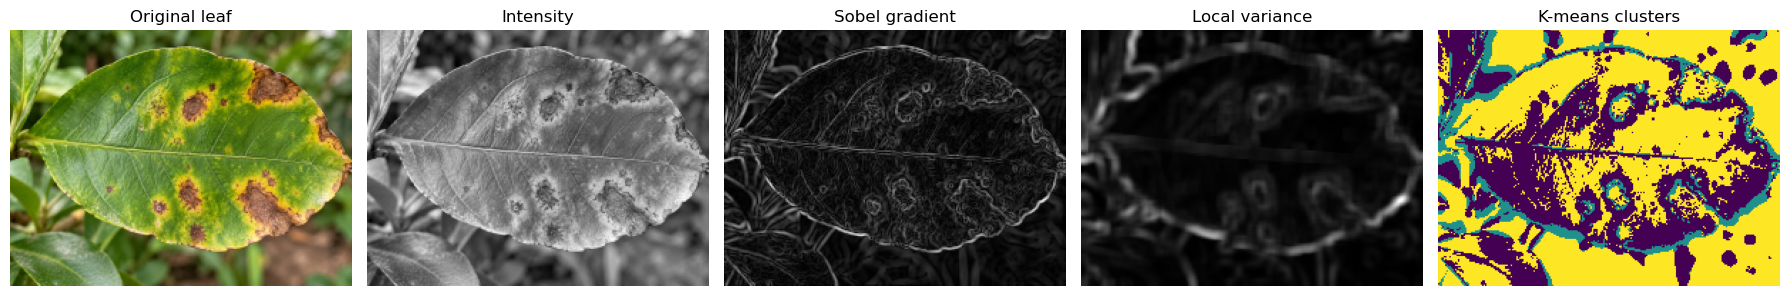

Average feature values by cluster:
Cluster 0: intensity=0.606, gradient=0.120, local_variance=0.085, pixels=15622
Cluster 1: intensity=0.488, gradient=0.313, local_variance=0.276, pixels=4351
Cluster 2: intensity=0.371, gradient=0.070, local_variance=0.050, pixels=23227

Observations:
- Intensity can help distinguish brown/dark discoloured areas from green areas.
- Gradient magnitude highlights boundaries and leaf veins.
- Local variance highlights areas with irregular texture.
- Compare the feature maps and cluster averages to judge which feature helps most.
- Shadows, veins and background pixels can be misclassified. K-means is unsupervised and does not know true disease labels.


In [9]:
#Problem 6 – Multi-Feature Segmentation for Disease Detection
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

bgr = cv2.imread("plant_leaf.jpg")
if bgr is None:
    raise FileNotFoundError("plant_leaf.jpg not found. Extract the sample ZIP beside this notebook.")
bgr = cv2.resize(bgr, (240, 180), interpolation=cv2.INTER_AREA)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)

intensity = gray.astype(np.float32) / 255.0

gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
gradient = cv2.magnitude(gx, gy)
gradient /= (gradient.max() + 1e-8)

g = gray.astype(np.float32)
mean = cv2.blur(g, (9, 9))
mean_square = cv2.blur(g*g, (9, 9))
local_variance = np.maximum(mean_square - mean*mean, 0)
local_variance /= (local_variance.max() + 1e-8)

feature_image = np.dstack([intensity, gradient, local_variance])
X = feature_image.reshape(-1, 3)
X_scaled = StandardScaler().fit_transform(X)
cluster_ids = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled)
segmentation = cluster_ids.reshape(gray.shape)

fig, ax = plt.subplots(1, 5, figsize=(18, 5))
images = [rgb, intensity, gradient, local_variance, segmentation]
titles = ["Original leaf", "Intensity", "Sobel gradient", "Local variance", "K-means clusters"]
for a, im, title in zip(ax, images, titles):
    a.imshow(im, cmap=None if title == "Original leaf" else "viridis" if title == "K-means clusters" else "gray")
    a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

print("Average feature values by cluster:")
for cluster in range(3):
    values = feature_image[segmentation == cluster]
    print(f"Cluster {cluster}: intensity={values[:,0].mean():.3f}, "
          f"gradient={values[:,1].mean():.3f}, "
          f"local_variance={values[:,2].mean():.3f}, pixels={len(values)}")

print("\nObservations:")
print("- Intensity can help distinguish brown/dark discoloured areas from green areas.")
print("- Gradient magnitude highlights boundaries and leaf veins.")
print("- Local variance highlights areas with irregular texture.")
print("- Compare the feature maps and cluster averages to judge which feature helps most.")
print("- Shadows, veins and background pixels can be misclassified. K-means is unsupervised and does not know true disease labels.")